# Stage 5 — 3D LiDAR Object Detection with a Pretrained Model

## Objective

The objective of this stage is to explore 3D object detection using LiDAR point clouds and a pretrained deep learning model. Unlike previous stages, which focused on detecting objects in RGB images using YOLO, this stage investigates how neural networks can identify and localize objects directly from 3D spatial data.

We will use PointPillars, a pretrained LiDAR-based 3D object detection model, to perform inference on point clouds from the Seeing Through Fog dataset.

The main goals are to:

- Understand the fundamentals of 3D object detection and how PointPillars processes LiDAR point clouds.
- Set up the environment and load a pretrained model without training it from scratch.
- Run inference on real LiDAR frames from the dataset.
- Visualize the predicted 3D bounding boxes and detected object classes.
- Explore the model's performance and limitations when applied to data from a different dataset and sensor configuration than the one used for pretraining.

This stage will provide an initial comparison between image-based object detection and LiDAR-based 3D object detection, establishing a foundation for future multimodal sensor evaluation and fusion.

In [1]:
import inspect
import torch
import torch_pointcloud as tp

model, info = tp.create_model(
    "pointpillars.kitti.openpcdet",
    task="detection",
    pretrained=True,
    return_info=True,
)

print("Model class:", type(model))

print("\nForward signature:")
print(inspect.signature(model.forward))

print("\nModel methods:")
print([m for m in dir(model) if not m.startswith("_")])

/home/maritza/projects/autonomous_vehicle/.venv_stage5_pointcloud/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model class: <class 'torch_pointcloud.models.pointpillars.PointPillarsDetection'>

Forward signature:
(voxels: torch.Tensor, pos_voxel: torch.Tensor, voxel_num_points: torch.Tensor, batch: torch.Tensor) -> torch_pointcloud.layers.anchors.AnchorHeadOutput

Model methods:
['T_destination', 'act', 'act_kwargs', 'add_module', 'align_center', 'anchor_bottom_heights', 'anchor_range', 'anchor_rotations', 'anchor_sizes', 'apply', 'backbone', 'bfloat16', 'buffers', 'call_super_init', 'children', 'code_size', 'compile', 'configure_backbone', 'configure_head', 'configure_vfe', 'cpu', 'cuda', 'decode', 'dir_limit_offset', 'dir_offset', 'double', 'dump_patches', 'eval', 'extra_repr', 'feat_channels', 'feature_map_stride', 'float', 'forward', 'forward_features', 'forward_head', 'get_buffer', 'get_extra_state', 'get_parameter', 'get_submodule', 'grid_size', 'half', 'head', 'in_channels', 'ipu', 'layer_nums', 'layer_strides', 'load_state_dict', 'modules', 'mtia', 'named_buffers', 'named_children', 'na

In [2]:
print("MODEL CONFIGURATION")
print("===================")

print("\nNumber of classes:")
print(model.num_classes)

print("\nVoxel size:")
print(model.voxel_size)

print("\nPoint cloud range:")
print(model.point_cloud_range)

print("\nGrid size:")
print(model.grid_size)

print("\nCheckpoint classes:")
print(info["weights"]["classes"])

print("\nPREPROCESSING TRANSFORM")
print("=======================")
print(info["transform"])

MODEL CONFIGURATION

Number of classes:
3

Voxel size:
(0.16, 0.16, 4.0)

Point cloud range:
(0.0, -39.68, -3.0, 69.12, 39.68, 1.0)

Grid size:
(432, 496, 1)

Checkpoint classes:
('Car', 'Pedestrian', 'Cyclist')

PREPROCESSING TRANSFORM
Compose(
  Cat(keys=('intensity',), allow_missing_keys=False, dst_key='x', dim=1),
  HardVoxelize(keys=('pos',), allow_missing_keys=False, pos_key='pos', voxel_size=(0.16, 0.16, 4.0), point_cloud_range=(0.0, -39.68, -3.0, 69.12, 39.68, 1.0), max_num_points=32, max_num_voxels=40000, feature_key='x', dst_voxel_key='voxel', dst_pos_voxel_key='pos_voxel', dst_num_points_key='voxel_num_points')
)


In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

LIDAR_DIR = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "extracted"
    / "lidar_hdl64_last"
    / "lidar_hdl64_last"
)

print("Project root:", PROJECT_ROOT)
print("LiDAR directory:", LIDAR_DIR)
print("Directory exists:", LIDAR_DIR.exists())

Project root: /home/maritza/projects/autonomous_vehicle
LiDAR directory: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/lidar_hdl64_last/lidar_hdl64_last
Directory exists: True


In [4]:
import numpy as np
from pathlib import Path

# Find one LiDAR frame
lidar_files = sorted(Path(LIDAR_DIR).glob("*.bin"))

print("Number of LiDAR files:", len(lidar_files))

sample_path = lidar_files[0]

# Load point cloud
points = np.fromfile(sample_path, dtype=np.float32)
points = points.reshape(-1, 5)

print("\nSample:", sample_path.name)
print("Point cloud shape:", points.shape)

# Inspect the five columns
column_names = [
    "X",
    "Y",
    "Z",
    "Column 4 (candidate intensity)",
    "Column 5 (candidate channel ID)"
]

for i, name in enumerate(column_names):
    values = points[:, i]

    print(f"\n{name}")
    print("  Min:", np.min(values))
    print("  Max:", np.max(values))
    print("  Mean:", np.mean(values))
    print("  Median:", np.median(values))
    print("  Unique values:", len(np.unique(values)))

Number of LiDAR files: 12997

Sample: 2018-02-03_20-48-35_00400.bin
Point cloud shape: (110514, 5)

X
  Min: -109.048294
  Max: 109.91262
  Mean: 1.0764425
  Median: 0.08747488
  Unique values: 110420

Y
  Min: -80.57042
  Max: 42.35243
  Mean: -0.47048
  Median: 0.043086156
  Unique values: 110240

Z
  Min: -36.35103
  Max: 3.764115
  Mean: -0.9101641
  Median: -0.9811966
  Unique values: 40395

Column 4 (candidate intensity)
  Min: 24.0
  Max: 255.0
  Mean: 150.13991
  Median: 150.6
  Unique values: 4539

Column 5 (candidate channel ID)
  Min: 0.0
  Max: 63.0
  Mean: 31.416744
  Median: 31.0
  Unique values: 64


In [5]:
# PointPillars spatial limits
x_min, y_min, z_min = 0.0, -39.68, -3.0
x_max, y_max, z_max = 69.12, 39.68, 1.0

xyz = points[:, :3]

inside_range = (
    (xyz[:, 0] >= x_min) & (xyz[:, 0] < x_max) &
    (xyz[:, 1] >= y_min) & (xyz[:, 1] < y_max) &
    (xyz[:, 2] >= z_min) & (xyz[:, 2] < z_max)
)

print("Total points:", len(points))
print("Points inside KITTI range:", inside_range.sum())
print("Points outside KITTI range:", (~inside_range).sum())

print(
    "Percentage inside:",
    round(inside_range.mean() * 100, 2),
    "%"
)

Total points: 110514
Points inside KITTI range: 54496
Points outside KITTI range: 56018
Percentage inside: 49.31 %


In [6]:
for i in range(3, 5):
    values = points[:, i]

    print(f"\nCOLUMN {i + 1}")
    print("=" * 35)

    print("Min:", values.min())
    print("Max:", values.max())
    print("Mean:", values.mean())
    print("Median:", np.median(values))
    print("Standard deviation:", values.std())
    print("Unique values:", len(np.unique(values)))

    print("First 15 values:", values[:15])


COLUMN 4
Min: 24.0
Max: 255.0
Mean: 150.13991
Median: 150.6
Standard deviation: 75.75034
Unique values: 4539
First 15 values: [255.  243.  247.4 255.  255.  255.  159.  255.  243.8 255.  255.  255.
 255.  251.9 255. ]

COLUMN 5
Min: 0.0
Max: 63.0
Mean: 31.416744
Median: 31.0
Standard deviation: 18.453651
Unique values: 64
First 15 values: [36. 37. 58. 59. 38. 39. 32. 33. 40. 41. 34. 35. 48. 49. 42.]


In [7]:
print("AXIS DISTRIBUTION")
print("=" * 45)

for i, axis in enumerate(["X", "Y", "Z"]):
    values = points[:, i]

    print(f"\n{axis}")
    print("5th percentile:", np.percentile(values, 5))
    print("25th percentile:", np.percentile(values, 25))
    print("50th percentile:", np.percentile(values, 50))
    print("75th percentile:", np.percentile(values, 75))
    print("95th percentile:", np.percentile(values, 95))

AXIS DISTRIBUTION

X
5th percentile: -15.188548
25th percentile: -2.2984347
50th percentile: 0.08747488
75th percentile: 5.041423
95th percentile: 17.26959

Y
5th percentile: -12.277818
25th percentile: -4.8219843
50th percentile: 0.043086156
75th percentile: 5.3286934
95th percentile: 8.815339

Z
5th percentile: -1.7305453
25th percentile: -1.5175344
50th percentile: -0.9811966
75th percentile: -0.25414354
95th percentile: 0.3877266


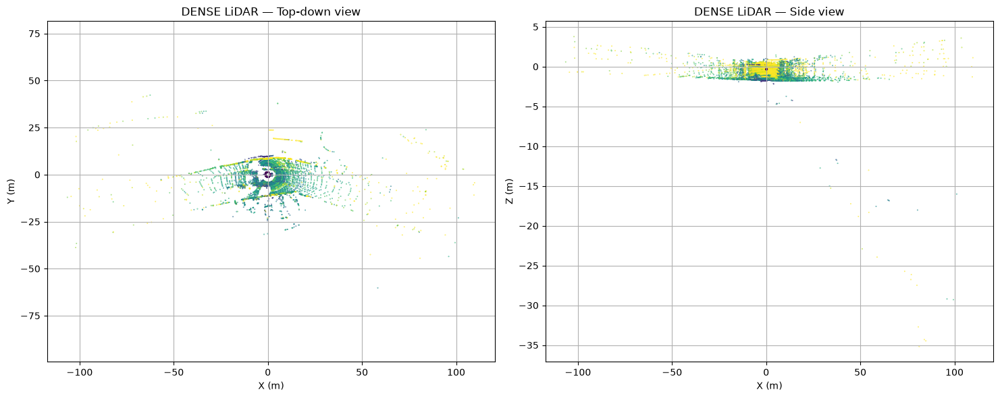

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top-down view
axes[0].scatter(
    points[::10, 0],
    points[::10, 1],
    s=0.1,
    c=points[::10, 3],
    cmap="viridis"
)
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].set_title("DENSE LiDAR — Top-down view")
axes[0].axis("equal")
axes[0].grid(True)

# Side view
axes[1].scatter(
    points[::10, 0],
    points[::10, 2],
    s=0.1,
    c=points[::10, 3],
    cmap="viridis"
)
axes[1].set_xlabel("X (m)")
axes[1].set_ylabel("Z (m)")
axes[1].set_title("DENSE LiDAR — Side view")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [9]:
import json
from pathlib import Path

calib_path = (
    PROJECT_ROOT
    / "SeeingThroughFog"
    / "tools"
    / "DatasetViewer"
    / "calibs"
    / "calib_tf_tree_full.json"
)

print("Calibration exists:", calib_path.exists())

Calibration exists: False


In [10]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

calibration_files = list(
    PROJECT_ROOT.rglob("calib_tf_tree_full.json")
)

print("Calibration files found:", len(calibration_files))

for file in calibration_files:
    print(file)

import json

calib_path = calibration_files[0]

with open(calib_path, "r") as f:
    calib = json.load(f)

print(json.dumps(calib, indent=2)[:5000])

Calibration files found: 1
/home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/downloads/calibration/calib_tf_tree_full.json
[
  {
    "header": {
      "stamp": {
        "secs": 1518427330,
        "nsecs": 764094035
      },
      "frame_id": "cam_stereo_left_optical",
      "seq": 0
    },
    "transform": {
      "translation": {
        "y": 0.0,
        "x": 0.0,
        "z": 0.0
      },
      "rotation": {
        "y": 0.5,
        "x": -0.5,
        "z": -0.4999999999999999,
        "w": -0.5000000000000001
      }
    },
    "child_frame_id": "cam_stereo_left_visual"
  },
  {
    "header": {
      "stamp": {
        "secs": 1518427330,
        "nsecs": 764088920
      },
      "frame_id": "body",
      "seq": 0
    },
    "transform": {
      "translation": {
        "y": -0.00125,
        "x": 1.4185,
        "z": 1.30225
      },
      "rotation": {
        "y": -0.006999886834005389,
        "x": -2.7999696667896407e-05,
        "z": -0.003999891334003365

In [11]:
z = points[:, 2]

print("Z < -3 m:", np.sum(z < -3))
print("Z > 1 m:", np.sum(z > 1))

distance = np.linalg.norm(points[:, :3], axis=1)

print("\nDistance from sensor:")
print("Median:", np.median(distance))
print("95th percentile:", np.percentile(distance, 95))
print("99th percentile:", np.percentile(distance, 99))

Z < -3 m: 488
Z > 1 m: 1213

Distance from sensor:
Median: 8.438652
95th percentile: 26.306992
99th percentile: 74.097885


In [12]:
import numpy as np
from scipy.spatial.transform import Rotation

# Find the LiDAR calibration entry
lidar_transform = next(
    item for item in calib
    if item["child_frame_id"] == "lidar_hdl64_s3_roof"
)

translation = lidar_transform["transform"]["translation"]
rotation = lidar_transform["transform"]["rotation"]

# Translation vector
t_body_lidar = np.array([
    translation["x"],
    translation["y"],
    translation["z"]
])

# SciPy quaternion order: x, y, z, w
q = [
    rotation["x"],
    rotation["y"],
    rotation["z"],
    rotation["w"]
]

R_body_lidar = Rotation.from_quat(q).as_matrix()

# Homogeneous transformation: LiDAR -> body
T_body_lidar = np.eye(4)
T_body_lidar[:3, :3] = R_body_lidar
T_body_lidar[:3, 3] = t_body_lidar

print("Translation:")
print(t_body_lidar)

print("\nRotation matrix:")
print(R_body_lidar)

print("\nHomogeneous transformation:")
print(T_body_lidar)

Translation:
[ 1.41850e+00 -1.25000e-03  1.30225e+00]

Rotation matrix:
[[ 9.99870005e-01  7.99991467e-03 -1.39990947e-02]
 [-7.99913069e-03  9.99968000e-01  1.11995147e-04]
 [ 1.39995427e-02  0.00000000e+00  9.99902002e-01]]

Homogeneous transformation:
[[ 9.99870005e-01  7.99991467e-03 -1.39990947e-02  1.41850000e+00]
 [-7.99913069e-03  9.99968000e-01  1.11995147e-04 -1.25000000e-03]
 [ 1.39995427e-02  0.00000000e+00  9.99902002e-01  1.30225000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [13]:
# Original LiDAR coordinates
xyz_lidar = points[:, :3]

# Transform LiDAR coordinates into body coordinates
xyz_homogeneous = np.column_stack([
    xyz_lidar,
    np.ones(len(xyz_lidar))
])

xyz_body = (
    T_body_lidar @ xyz_homogeneous.T
).T[:, :3]

# PointPillars KITTI limits
point_cloud_range = np.array([
    0.0, -39.68, -3.0,
    69.12, 39.68, 1.0
])

def check_range(xyz, name):
    mask = (
        (xyz[:, 0] >= point_cloud_range[0]) &
        (xyz[:, 1] >= point_cloud_range[1]) &
        (xyz[:, 2] >= point_cloud_range[2]) &
        (xyz[:, 0] < point_cloud_range[3]) &
        (xyz[:, 1] < point_cloud_range[4]) &
        (xyz[:, 2] < point_cloud_range[5])
    )

    print(f"\n{name}")
    print("Points inside range:", mask.sum())
    print("Percentage:", round(mask.mean() * 100, 2), "%")

    print("X range:", xyz[:, 0].min(), xyz[:, 0].max())
    print("Y range:", xyz[:, 1].min(), xyz[:, 1].max())
    print("Z range:", xyz[:, 2].min(), xyz[:, 2].max())

    return mask

mask_lidar = check_range(xyz_lidar, "Original LiDAR frame")
mask_body = check_range(xyz_body, "Transformed body frame")


Original LiDAR frame
Points inside range: 54496
Percentage: 49.31 %
X range: -109.048294 109.91262
Y range: -80.57042 42.35243
Z range: -36.35103 3.764115

Transformed body frame
Points inside range: 54616
Percentage: 49.42 %
X range: -107.53342062651716 111.27213486511022
Y range: -81.07017998452848 42.84474896022948
Z range: -33.793549621544216 6.575398162600906


In [14]:
intensity_candidate = points[:, 3]
distance = np.linalg.norm(points[:, :3], axis=1)

print("Candidate intensity statistics")
print("Min:", intensity_candidate.min())
print("Max:", intensity_candidate.max())
print("Mean:", intensity_candidate.mean())

print("\nIntensity percentiles:")
print(np.percentile(intensity_candidate, [0, 25, 50, 75, 95, 99, 100]))

print("\nIntensity-distance correlation:")
print(np.corrcoef(intensity_candidate, distance)[0, 1])

Candidate intensity statistics
Min: 24.0
Max: 255.0
Mean: 150.13991

Intensity percentiles:
[ 24.         105.         150.6000061  215.20000839 255.
 255.         255.        ]

Intensity-distance correlation:
0.4029381666816281


In [15]:
import numpy as np
from pathlib import Path

# Select one LiDAR frame
sample_file = LIDAR_DIR / "2018-02-03_20-48-35_00400.bin"

# Load the point cloud
raw_points = np.fromfile(sample_file, dtype=np.float32).reshape(-1, 5)

# Extract XYZ coordinates and intensity
points = raw_points[:, :4].copy()

# Apply PointPillars KITTI point cloud range
point_cloud_range = np.array([
    0, -39.68, -3,
    69.12, 39.68, 1
])

mask = (
    (points[:, 0] >= point_cloud_range[0]) &
    (points[:, 0] < point_cloud_range[3]) &
    (points[:, 1] >= point_cloud_range[1]) &
    (points[:, 1] < point_cloud_range[4]) &
    (points[:, 2] >= point_cloud_range[2]) &
    (points[:, 2] < point_cloud_range[5])
)

points = points[mask]

print("Frame:", sample_file.name)
print("Raw points:", len(raw_points))
print("Points inside model range:", len(points))
print("Point array shape:", points.shape)
print("XYZ min:", points[:, :3].min(axis=0))
print("XYZ max:", points[:, :3].max(axis=0))
print("Intensity min/max:", points[:, 3].min(), points[:, 3].max())



Frame: 2018-02-03_20-48-35_00400.bin
Raw points: 110514
Points inside model range: 54496
Point array shape: (54496, 4)
XYZ min: [ 1.6223639e-05 -3.1428669e+01 -2.8335805e+00]
XYZ max: [69.11973    24.202873    0.99988794]
Intensity min/max: 24.0 255.0


In [16]:
import torch

# Prepare PointPillars input
sample = {
    "pos": torch.from_numpy(points[:, :3].copy()).float().cuda(),
    "intensity": torch.from_numpy(points[:, 3:4].copy()).float().cuda(),
}

# Apply the model's preprocessing pipeline
voxelized = info["transform"](sample)

# Inspect the generated tensors
for key, value in voxelized.items():
    if torch.is_tensor(value):
        print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}, device={value.device}")
    else:
        print(f"{key}: {type(value)}")

pos: shape=(54496, 3), dtype=torch.float32, device=cuda:0
intensity: shape=(54496, 1), dtype=torch.float32, device=cuda:0
x: shape=(54496, 1), dtype=torch.float32, device=cuda:0
voxel: shape=(9262, 32, 4), dtype=torch.float32, device=cuda:0
pos_voxel: shape=(9262, 3), dtype=torch.int32, device=cuda:0
voxel_num_points: shape=(9262,), dtype=torch.int32, device=cuda:0


In [19]:
# Inspect model parameter devices
devices = {}

for name, parameter in model.named_parameters():
    device = str(parameter.device)
    devices[device] = devices.get(device, 0) + parameter.numel()

print("Model parameters by device:")
for device, count in devices.items():
    print(f"{device}: {count:,} parameters")

print("\nInput tensors:")
print("voxels:", voxels.device)
print("pos_voxel:", pos_voxel.device)
print("voxel_num_points:", voxel_num_points.device)
print("batch:", batch.device)

# Move PointPillars model to GPU
model = model.to("cuda:0")
model.eval()

# Verify model device
print("Model device:", next(model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

Model parameters by device:
cpu: 4,834,888 parameters

Input tensors:
voxels: cuda:0
pos_voxel: cuda:0
voxel_num_points: cuda:0
batch: cuda:0
Model device: cuda:0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [21]:
# Prepare model inputs
voxels = voxelized["voxel"]
pos_voxel = voxelized["pos_voxel"]
voxel_num_points = voxelized["voxel_num_points"]

# Single-frame batch: all voxels belong to sample 0
batch = torch.zeros(
    len(voxels),
    dtype=torch.long,
    device=voxels.device
)

# Run PointPillars
with torch.no_grad():
    output = model(
        voxels,
        pos_voxel,
        voxel_num_points,
        batch
    )

print("Model output type:", type(output))
print("Model output:", output)

Model output type: <class 'dict'>
Model output: {'cls': tensor([[[[ -9.4112, -13.2548, -13.3191,  ..., -13.1851, -13.3801, -23.8116],
          [ -9.4048, -12.3120, -12.0410,  ..., -12.2594, -12.3170, -25.2952],
          [ -9.9514, -13.3566, -13.2276,  ..., -13.3669, -13.5961, -24.4031],
          ...,
          [ -4.5706, -10.7335, -10.6006,  ..., -10.6913, -10.6068,  -6.0526],
          [ -4.5083, -10.5039, -10.4372,  ..., -10.5072, -10.5050,  -5.8882],
          [ -3.9459, -10.5911, -10.5299,  ..., -10.5581, -10.4909,  -5.4926]],

         [[ -9.0350, -12.8330, -12.8689,  ..., -12.8875, -12.9280, -27.5446],
          [ -9.2773, -11.9515, -11.7254,  ..., -12.1778, -11.9087, -23.5611],
          [ -9.8679, -12.1495, -11.8696,  ..., -12.1255, -12.0043, -23.8346],
          ...,
          [ -5.2252, -10.5455, -10.5929,  ..., -10.5810, -10.5788,  -7.7906],
          [ -4.4999, -10.4109, -10.3437,  ..., -10.4012, -10.3518,  -7.2569],
          [ -4.8842, -10.5273, -10.5939,  ..., -10.601

In [22]:
import inspect

print("Decode signature:")
print(inspect.signature(model.decode))

print("\nDecode source:")
print(inspect.getsource(model.decode))

Decode signature:
(out: torch_pointcloud.layers.anchors.AnchorHeadOutput) -> torch_pointcloud.utils.types.Detection3D

Decode source:
    @torch.no_grad()
    def decode(self, out: AnchorHeadOutput) -> Detection3D:
        r"""Decode a forward output into raw per-anchor detections (see `AnchorHead.decode`)."""
        return self.head.decode(out)



In [24]:
print("Detection type:", type(detections))

print("\nAvailable keys:")
print(detections.keys())

print("\nDetection contents:")
for key, value in detections.items():
    if torch.is_tensor(value):
        print(
            f"{key}: shape={tuple(value.shape)}, "
            f"dtype={value.dtype}, device={value.device}"
        )
        if value.numel() > 0:
            print("  Sample:", value.flatten()[:10])
    else:
        print(f"{key}: {type(value)}")
        print("  Value:", value)

Detection type: <class 'dict'>

Available keys:
dict_keys(['boxes', 'scores', 'labels', 'batch', 'class_probs'])

Detection contents:
boxes: shape=(321408, 7), dtype=torch.float32, device=cuda:0
  Sample: tensor([  2.5415, -38.9539,  -2.4296,   3.9153,   1.7467,   1.8510,   5.5553,
          2.2465, -39.2112,  -1.5413], device='cuda:0')
scores: shape=(321408,), dtype=torch.float32, device=cuda:0
  Sample: tensor([8.1799e-05, 1.8306e-06, 1.8355e-06, 3.3353e-06, 1.9040e-06, 1.8784e-06,
        8.2319e-05, 5.0936e-06, 5.1350e-06, 7.8846e-06], device='cuda:0')
labels: shape=(321408,), dtype=torch.int64, device=cuda:0
  Sample: tensor([0, 1, 2, 0, 1, 0, 0, 1, 2, 0], device='cuda:0')
batch: shape=(321408,), dtype=torch.int64, device=cuda:0
  Sample: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')
class_probs: shape=(321408, 3), dtype=torch.float32, device=cuda:0
  Sample: tensor([8.1799e-05, 1.7519e-06, 1.6427e-06, 1.8395e-08, 1.8306e-06, 1.5579e-06,
        1.4673e-06, 6.1174e-11, 1

In [25]:
# Analyze prediction confidence scores
scores = detections["scores"]

print("Total predictions:", len(scores))
print("Minimum score:", scores.min().item())
print("Maximum score:", scores.max().item())
print("Mean score:", scores.mean().item())
print("Median score:", scores.median().item())

print("\nScore percentiles:")
for p in [50, 75, 90, 95, 99, 99.5, 99.9]:
    value = torch.quantile(scores, p / 100).item()
    print(f"P{p}: {value:.6f}")

print("\nPredictions above thresholds:")
for threshold in [0.01, 0.05, 0.1, 0.25, 0.5]:
    count = (scores >= threshold).sum().item()
    print(f">= {threshold:.2f}: {count}")

Total predictions: 321408
Minimum score: 0.0
Maximum score: 1.0
Mean score: 0.000324453751090914
Median score: 2.362742163378173e-12

Score percentiles:
P50: 0.000000
P75: 0.000004
P90: 0.000781
P95: 0.001979
P99: 0.004729
P99.5: 0.006617
P99.9: 0.013510

Predictions above thresholds:
>= 0.01: 683
>= 0.05: 20
>= 0.10: 9
>= 0.25: 9
>= 0.50: 8


In [26]:
# Inspect the 20 highest-confidence predictions
scores = detections["scores"]
top_scores, top_indices = torch.topk(scores, k=20)

top_labels = detections["labels"][top_indices]
top_boxes = detections["boxes"][top_indices]

class_names = ["Car", "Pedestrian", "Cyclist"]

print(f"{'Rank':<6}{'Class':<15}{'Confidence':<15}{'X':<10}{'Y':<10}{'Z':<10}")

for i in range(len(top_indices)):
    label = top_labels[i].item()
    box = top_boxes[i].cpu().numpy()

    print(
        f"{i+1:<6}"
        f"{class_names[label]:<15}"
        f"{top_scores[i].item():<15.5f}"
        f"{box[0]:<10.2f}"
        f"{box[1]:<10.2f}"
        f"{box[2]:<10.2f}"
    )

Rank  Class          Confidence     X         Y         Z         
1     Cyclist        1.00000        75.39     -29.39    3.02      
2     Cyclist        1.00000        76.41     -7.53     4.51      
3     Car            0.99999        78.17     -34.05    19.87     
4     Cyclist        0.99998        68.49     -24.65    2.75      
5     Cyclist        0.99992        68.80     8.26      0.09      
6     Cyclist        0.99977        54.65     -3.56     -0.98     
7     Cyclist        0.98711        51.57     12.19     0.49      
8     Cyclist        0.53730        35.22     19.73     2.00      
9     Cyclist        0.34204        79.94     -27.42    1.73      
10    Car            0.07886        68.55     19.40     -1.58     
11    Cyclist        0.06566        68.11     -28.92    -1.13     
12    Car            0.06522        60.40     -36.50    -1.40     
13    Car            0.05740        69.07     18.33     -1.69     
14    Car            0.05674        68.62     19.09     -1.72 

Predictions above confidence threshold: 20
Predictions inside model range: 147501
Predictions selected for visualization: 14


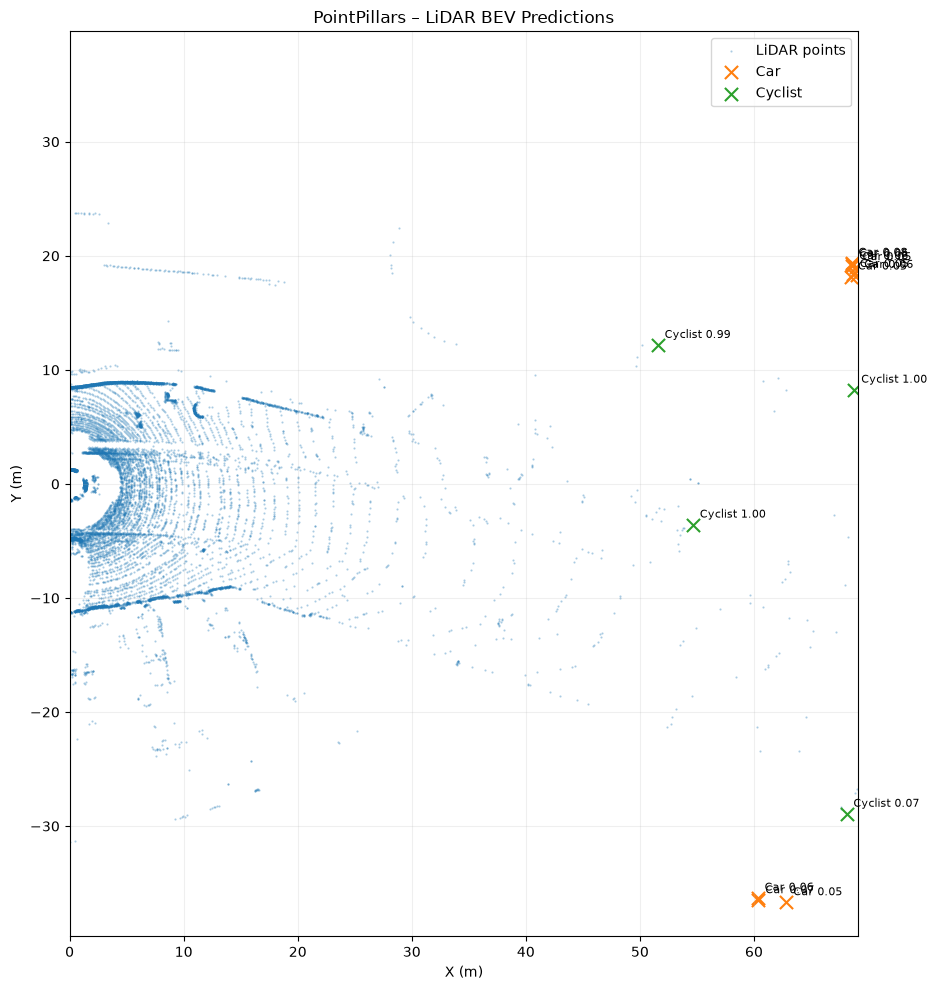

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Convert point cloud to CPU for visualization
points_np = points[:, :3].cpu().numpy() if torch.is_tensor(points) else points[:, :3]

# Extract predictions
boxes = detections["boxes"].detach().cpu().numpy()
scores = detections["scores"].detach().cpu().numpy()
labels = detections["labels"].detach().cpu().numpy()

class_names = ["Car", "Pedestrian", "Cyclist"]

# Keep predictions above confidence threshold
confidence_threshold = 0.05

# Check whether box centers are inside the model range
inside_range = (
    (boxes[:, 0] >= 0) & (boxes[:, 0] < 69.12) &
    (boxes[:, 1] >= -39.68) & (boxes[:, 1] < 39.68) &
    (boxes[:, 2] >= -3) & (boxes[:, 2] < 1)
)

valid_mask = (scores >= confidence_threshold) & inside_range

valid_boxes = boxes[valid_mask]
valid_scores = scores[valid_mask]
valid_labels = labels[valid_mask]

print("Predictions above confidence threshold:", (scores >= confidence_threshold).sum())
print("Predictions inside model range:", inside_range.sum())
print("Predictions selected for visualization:", len(valid_boxes))

# Plot BEV
fig, ax = plt.subplots(figsize=(14, 10))

# LiDAR points
ax.scatter(
    points_np[::5, 0],
    points_np[::5, 1],
    s=0.3,
    alpha=0.35,
    label="LiDAR points"
)

# Predicted object centers
for class_id, class_name in enumerate(class_names):
    mask = valid_labels == class_id

    if not mask.any():
        continue

    ax.scatter(
        valid_boxes[mask, 0],
        valid_boxes[mask, 1],
        s=90,
        marker="x",
        label=class_name
    )

# Annotate confidence scores
for box, score, label in zip(valid_boxes, valid_scores, valid_labels):
    ax.annotate(
        f"{class_names[label]} {score:.2f}",
        (box[0], box[1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlim(0, 69.12)
ax.set_ylim(-39.68, 39.68)
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_title("PointPillars – LiDAR BEV Predictions")
ax.legend()
ax.grid(alpha=0.2)
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [34]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd()

# RGB image directory
RGB_DIR = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "extracted"
    / "cam_stereo_left_lut"
    / "cam_stereo_left_lut"
)

print("RGB directory:", RGB_DIR)
print("Directory exists:", RGB_DIR.exists())

import json
import numpy as np
from pathlib import Path

CALIB_PATH = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "downloads"
    / "calibration"
    / "calib_tf_tree_full.json"
)

with open(CALIB_PATH, "r") as f:
    calib_data = json.load(f)

print("Calibration loaded:", CALIB_PATH.exists())

RGB directory: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/cam_stereo_left_lut/cam_stereo_left_lut
Directory exists: True
Calibration loaded: True


In [36]:
from scipy.spatial.transform import Rotation

# Load camera calibration
CAMERA_CALIB_PATH = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "downloads"
    / "calibration"
    / "calib_cam_stereo_left.json"
)

with open(CAMERA_CALIB_PATH, "r") as f:
    camera_calib = json.load(f)

# Find the camera and LiDAR transforms
camera_entry = next(
    item for item in calib_data
    if item["child_frame_id"] == "cam_stereo_left_optical"
)

lidar_entry = next(
    item for item in calib_data
    if item["child_frame_id"] == "lidar_hdl64_s3_roof"
)

def make_transform(entry):
    t = entry["transform"]
    translation = t["translation"]
    rotation = t["rotation"]

    matrix = np.eye(4)
    matrix[:3, :3] = Rotation.from_quat([
        rotation["x"],
        rotation["y"],
        rotation["z"],
        rotation["w"]
    ]).as_matrix()

    matrix[:3, 3] = [
        translation["x"],
        translation["y"],
        translation["z"]
    ]

    return matrix

T_camera = make_transform(camera_entry)
T_lidar = make_transform(lidar_entry)

# LiDAR to camera transformation
T_camera_lidar = np.linalg.inv(T_camera) @ T_lidar

# Rectified camera projection matrix
P = np.asarray(camera_calib["P"]).reshape(3, 4)

# Final LiDAR-to-image projection
VTC = P @ T_camera_lidar

print("VTC shape:", VTC.shape)
print(VTC)

print("VTC:", VTC.shape)
print("RGB:", rgb_image.shape)
print("LiDAR:", points.shape)

VTC shape: (3, 4)
[[ 1.00731561e+03 -2.34756217e+03 -1.06708356e+01 -4.81188770e+02]
 [ 4.91165653e+02  7.62879023e+00 -2.35928902e+03 -1.33431015e+03]
 [ 9.99941060e-01  8.17631422e-03 -7.14315138e-03 -6.95557798e-01]]
VTC: (3, 4)
RGB: (1024, 1920, 3)
LiDAR: (54496, 4)


In [37]:
# Use the same points that entered PointPillars
xyz = points[:, :3]

# Homogeneous coordinates
xyz_h = np.column_stack([
    xyz,
    np.ones(len(xyz))
])

# Project LiDAR points into camera coordinates
projected = (VTC @ xyz_h.T).T

depth = projected[:, 2]

# Keep points in front of the camera
valid = depth > 0

u = projected[valid, 0] / depth[valid]
v = projected[valid, 1] / depth[valid]

projected_depth = depth[valid]

# Keep points inside image boundaries
h, w = rgb_image.shape[:2]

inside = (
    (u >= 0) & (u < w) &
    (v >= 0) & (v < h)
)

u = u[inside]
v = v[inside]
projected_depth = projected_depth[inside]

print("Input LiDAR points:", len(points))
print("Points in front of camera:", valid.sum())
print("Points projected inside RGB image:", len(u))

Input LiDAR points: 54496
Points in front of camera: 49620
Points projected inside RGB image: 8180


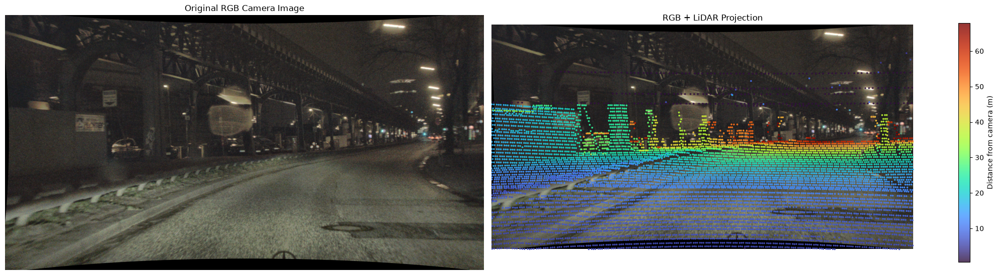

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Original RGB
axes[0].imshow(rgb_image)
axes[0].set_title("Original RGB Camera Image")
axes[0].axis("off")

# RGB + LiDAR projection
axes[1].imshow(rgb_image)

scatter = axes[1].scatter(
    u,
    v,
    c=projected_depth,
    cmap="turbo",
    s=3,
    alpha=0.8
)

axes[1].set_title("RGB + LiDAR Projection")
axes[1].axis("off")

fig.colorbar(
    scatter,
    ax=axes[1],
    label="Distance from camera (m)",
    fraction=0.025
)

plt.tight_layout()
plt.show()

Matched RGB-LiDAR frames: 12,997


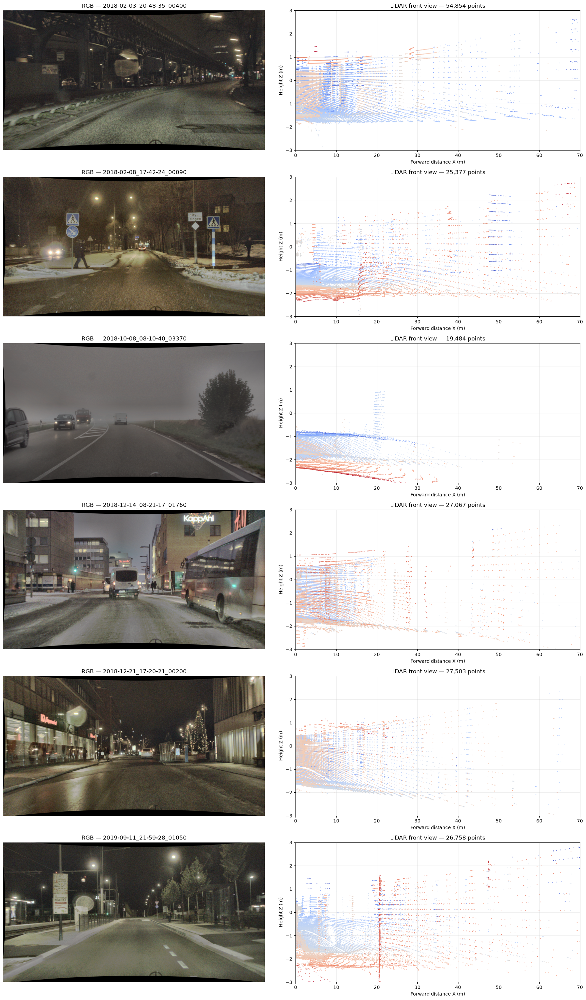

In [39]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import random

# Find LiDAR files that have a matching RGB image
lidar_files = sorted(LIDAR_DIR.glob("*.bin"))

matched_files = [
    f for f in lidar_files
    if (RGB_DIR / f"{f.stem}.png").exists()
]

print(f"Matched RGB-LiDAR frames: {len(matched_files):,}")

# Select six frames distributed across the dataset
n_examples = min(6, len(matched_files))
indices = np.linspace(
    0, len(matched_files) - 1, n_examples, dtype=int
)
selected_files = [matched_files[i] for i in indices]

fig, axes = plt.subplots(
    n_examples, 2,
    figsize=(18, 5 * n_examples)
)

if n_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for i, lidar_file in enumerate(selected_files):
    rgb_file = RGB_DIR / f"{lidar_file.stem}.png"

    # Load RGB image
    rgb = plt.imread(rgb_file)

    # Load raw LiDAR points
    raw = np.fromfile(lidar_file, dtype=np.float32).reshape(-1, 5)

    x = raw[:, 0]
    y = raw[:, 1]
    z = raw[:, 2]

    # Keep points in a useful forward-view range
    mask = (
        (x > 0) & (x < 70) &
        (y > -40) & (y < 40) &
        (z > -3) & (z < 3)
    )

    x_view = x[mask]
    y_view = y[mask]
    z_view = z[mask]

    # RGB image
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"RGB — {lidar_file.stem}")
    axes[i, 0].axis("off")

    # Front view: forward distance (X) vs height (Z)
    scatter = axes[i, 1].scatter(
        x_view,
        z_view,
        c=y_view,
        cmap="coolwarm",
        s=0.5,
        alpha=0.7
    )

    axes[i, 1].set_title(
        f"LiDAR front view — {len(x_view):,} points"
    )
    axes[i, 1].set_xlabel("Forward distance X (m)")
    axes[i, 1].set_ylabel("Height Z (m)")
    axes[i, 1].set_xlim(0, 70)
    axes[i, 1].set_ylim(-3, 3)
    axes[i, 1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# Inspect variables related to voxelization
[name for name in globals() if "voxel" in name.lower()]

# Inspect objects that may contain the voxelization transform
for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["transform", "voxel", "pipeline"]):
        print(
            f"{name}: {type(obj).__name__}"
        )

print("lidar_transform type:", type(lidar_transform))

for key, value in lidar_transform.items():
    print(f"{key}: {type(value).__name__}")


lidar_transform: dict
voxelized: dict
voxels: Tensor
pos_voxel: Tensor
voxel_num_points: Tensor
make_transform: function
lidar_transform type: <class 'dict'>
header: dict
transform: dict
child_frame_id: str
Model config:


AttributeError: 'PointPillarsDetection' object has no attribute 'config'

In [46]:
print("Model attributes:")
for name in dir(model):
    if any(k in name.lower() for k in [
        "voxel", "config", "transform", "range", "size"
    ]):
        try:
            value = getattr(model, name)
            if not callable(value):
                print(f"{name}: {value}")
        except Exception:
            pass

Model attributes:
anchor_range: None
anchor_sizes: [[3.9, 1.6, 1.56], [0.8, 0.6, 1.73], [1.76, 0.6, 1.73]]
code_size: 7
grid_size: (432, 496, 1)
point_cloud_range: (0.0, -39.68, -3.0, 69.12, 39.68, 1.0)
voxel_size: (0.16, 0.16, 4.0)


In [48]:
import inspect
import torch_pointcloud as tp

print("HardVoxelize location:")
print(inspect.getfile(tp.transforms.HardVoxelize))

import inspect
from torch_pointcloud.transforms.voxelization import HardVoxelize

print(inspect.signature(HardVoxelize))
print(inspect.getsource(HardVoxelize.__init__))

HardVoxelize location:
/home/maritza/projects/autonomous_vehicle/.venv_stage5_pointcloud/lib/python3.12/site-packages/torch_pointcloud/transforms/voxelization.py
(pos_key: str, voxel_size: Sequence[float], point_cloud_range: Sequence[float], max_num_points: int, max_num_voxels: int, feature_key: Optional[str] = None, dst_voxel_key: str = 'voxel', dst_pos_voxel_key: str = 'pos_voxel', dst_num_points_key: str = 'voxel_num_points', allow_missing_keys: bool = False) -> None
    def __init__(
        self,
        pos_key: str,
        voxel_size: Sequence[float],
        point_cloud_range: Sequence[float],
        max_num_points: int,
        max_num_voxels: int,
        feature_key: Optional[str] = None,
        dst_voxel_key: str = DataKeys.VOXEL,
        dst_pos_voxel_key: str = DataKeys.POS_VOXEL,
        dst_num_points_key: str = DataKeys.VOXEL_NUM_POINTS,
        allow_missing_keys: bool = False,
    ) -> None:
        super().__init__(keys=pos_key, allow_missing_keys=allow_missing_k

In [50]:
print("lidar_transform keys:", lidar_transform.keys())
print("Current voxelized keys:", voxelized.keys())

from torch_pointcloud.transforms.voxelization import HardVoxelize

voxelize = HardVoxelize(
    pos_key="pos",
    voxel_size=model.voxel_size,
    point_cloud_range=model.point_cloud_range,
    max_num_points=32,
    max_num_voxels=40000,
    feature_key="x"
)

print("Voxelizer created successfully")

lidar_transform keys: dict_keys(['header', 'transform', 'child_frame_id'])
Current voxelized keys: dict_keys(['pos', 'intensity', 'x', 'voxel', 'pos_voxel', 'voxel_num_points'])
Voxelizer created successfully


In [51]:
def run_pointpillars_on_frame(lidar_file, confidence_threshold=0.10):

    raw_points = np.fromfile(
        lidar_file, dtype=np.float32
    ).reshape(-1, 5)

    xyz = raw_points[:, :3]
    intensity = raw_points[:, 3:4]

    pc_range = model.point_cloud_range

    mask = (
        (xyz[:, 0] >= pc_range[0]) &
        (xyz[:, 1] >= pc_range[1]) &
        (xyz[:, 2] >= pc_range[2]) &
        (xyz[:, 0] < pc_range[3]) &
        (xyz[:, 1] < pc_range[4]) &
        (xyz[:, 2] < pc_range[5])
    )

    points = np.column_stack([
        xyz[mask], intensity[mask]
    ]).astype(np.float32)

    pos = torch.tensor(
        points[:, :3], dtype=torch.float32, device="cuda"
    )
    x = torch.tensor(
        points[:, 3:4], dtype=torch.float32, device="cuda"
    )

    voxelized = voxelize({
        "pos": pos,
        "x": x
    })

    voxels = voxelized["voxel"]
    pos_voxel = voxelized["pos_voxel"]
    voxel_num_points = voxelized["voxel_num_points"]

    batch = torch.zeros(
        len(voxels), dtype=torch.long, device=voxels.device
    )

    with torch.no_grad():
        output = model(
            voxels, pos_voxel, voxel_num_points, batch
        )
        predictions = model.decode(output)

    scores = predictions["scores"]
    keep = scores >= confidence_threshold

    print(f"\nFrame: {lidar_file.stem}")
    print(f"Input points: {len(points):,}")
    print(f"Voxels: {len(voxels):,}")
    print(f"Predictions >= {confidence_threshold}: {keep.sum().item()}")

    return predictions, keep, points

In [52]:
test_indices = [1, 2, 3]

results = {}

for idx in test_indices:
    lidar_file = selected_files[idx]

    predictions, keep, points = run_pointpillars_on_frame(
        lidar_file,
        confidence_threshold=0.10
    )

    results[lidar_file.stem] = {
        "predictions": predictions,
        "keep": keep,
        "points": points
    }


Frame: 2018-02-08_17-42-24_00090
Input points: 25,049
Voxels: 12,446
Predictions >= 0.1: 33

Frame: 2018-10-08_08-10-40_03370
Input points: 19,484
Voxels: 8,800
Predictions >= 0.1: 22

Frame: 2018-12-14_08-21-17_01760
Input points: 26,892
Voxels: 7,923
Predictions >= 0.1: 9


In [53]:
class_names = {
    0: "Car",
    1: "Pedestrian",
    2: "Cyclist"
}

for frame_name, result in results.items():

    predictions = result["predictions"]
    keep = result["keep"]

    boxes = predictions["boxes"][keep].detach().cpu().numpy()
    scores = predictions["scores"][keep].detach().cpu().numpy()
    labels = predictions["labels"][keep].detach().cpu().numpy()

    # Sort by confidence
    order = np.argsort(scores)[::-1]

    print(f"\n{'=' * 80}")
    print(f"FRAME: {frame_name}")
    print(f"{'=' * 80}")

    for rank, idx in enumerate(order[:10], start=1):
        box = boxes[idx]
        class_name = class_names.get(int(labels[idx]), "Unknown")

        print(
            f"{rank:2}. {class_name:10} | "
            f"Score: {scores[idx]:.3f} | "
            f"Center XYZ: ({box[0]:.2f}, {box[1]:.2f}, {box[2]:.2f}) | "
            f"Dimensions: ({box[3]:.2f}, {box[4]:.2f}, {box[5]:.2f}) | "
            f"Yaw: {box[6]:.2f}"
        )


FRAME: 2018-02-08_17-42-24_00090
 1. Cyclist    | Score: 1.000 | Center XYZ: (73.84, -4.50, 1.19) | Dimensions: (254.24, 502.07, 47.33) | Yaw: 4.91
 2. Cyclist    | Score: 1.000 | Center XYZ: (67.08, 37.30, -1.46) | Dimensions: (1.98, 9.63, 2.15) | Yaw: 3.89
 3. Cyclist    | Score: 1.000 | Center XYZ: (67.43, 24.60, -0.98) | Dimensions: (6.56, 701.74, 3.31) | Yaw: 1.98
 4. Cyclist    | Score: 1.000 | Center XYZ: (71.27, 0.38, -0.32) | Dimensions: (218.41, 6.08, 5.06) | Yaw: 4.95
 5. Cyclist    | Score: 0.999 | Center XYZ: (15.04, -32.03, -0.03) | Dimensions: (5.05, 0.00, 314.88) | Yaw: 5.12
 6. Cyclist    | Score: 0.992 | Center XYZ: (69.76, 37.66, 0.55) | Dimensions: (3.80, 13.75, 26.97) | Yaw: 5.88
 7. Cyclist    | Score: 0.971 | Center XYZ: (68.54, 37.36, -0.33) | Dimensions: (2.82, 0.82, 2.82) | Yaw: 6.29
 8. Cyclist    | Score: 0.970 | Center XYZ: (81.97, -5.11, -3.90) | Dimensions: (179095.09, 18254.98, 7.04) | Yaw: 5.81
 9. Cyclist    | Score: 0.959 | Center XYZ: (14.10, -28.37

In [55]:
import inspect

print("Decode implementation:")
print(inspect.getsource(type(model).decode))

print("Detection output type:")
decoded = model.decode(output)

print(type(decoded))
print("Keys:", decoded.keys())

for key, value in decoded.items():
    if torch.is_tensor(value):
        print(
            key,
            "shape:", tuple(value.shape),
            "dtype:", value.dtype,
            "device:", value.device
        )

Decode implementation:
    @torch.no_grad()
    def decode(self, out: AnchorHeadOutput) -> Detection3D:
        r"""Decode a forward output into raw per-anchor detections (see `AnchorHead.decode`)."""
        return self.head.decode(out)

Detection output type:
<class 'dict'>
Keys: dict_keys(['boxes', 'scores', 'labels', 'batch', 'class_probs'])
boxes shape: (321408, 7) dtype: torch.float32 device: cuda:0
scores shape: (321408,) dtype: torch.float32 device: cuda:0
labels shape: (321408,) dtype: torch.int64 device: cuda:0
batch shape: (321408,) dtype: torch.int64 device: cuda:0
class_probs shape: (321408, 3) dtype: torch.float32 device: cuda:0


In [56]:
import inspect

print(inspect.getsource(type(model.head).decode))

print("Head type:", type(model.head))
print("Head attributes:")

for name in dir(model.head):
    if any(k in name.lower() for k in [
        "anchor", "box", "coder", "decode", "nms", "range"
    ]):
        try:
            value = getattr(model.head, name)
            if not callable(value):
                print(f"{name}: {value}")
        except Exception:
            pass


boxes = decoded["boxes"].detach().cpu().numpy()
scores = decoded["scores"].detach().cpu().numpy()

print("Total raw anchors:", len(boxes))

for i, name in enumerate(["dx", "dy", "dz"]):
    values = boxes[:, i + 3]
    print(
        f"{name}: "
        f"min={np.nanmin(values):.4f}, "
        f"median={np.nanmedian(values):.4f}, "
        f"max={np.nanmax(values):.4f}"
    )

print("\nScore percentiles:")
for p in [50, 90, 95, 99, 99.9, 100]:
    print(f"P{p}: {np.nanpercentile(scores, p):.6f}")



    @torch.no_grad()
    def decode(self, out: AnchorHeadOutput) -> Detection3D:
        r"""Decode a forward output into raw per-anchor detections (no score threshold or NMS).

        Scores each anchor by its top sigmoid class probability and labels it by the argmax class. The
        full per-anchor set is returned; the evaluation pipeline applies score thresholding and per-class
        3D NMS via the `torch_pointcloud.ops.box3d` utilities (see the benchmark examples).

        Returns:
            Packed per-anchor detections `{"boxes": (B * A, 7), "scores": (B * A,), "labels": (B * A,),
            "batch": (B * A,), "class_probs": (B * A, C)}` (PyG layout), plus `"velocity"` $(B \cdot A, 2)$ when the
            box code carries it. The anchors come scene by scene, each scene in the order of `anchors`: feature-map
            row ($y$), column ($x$), anchor template, rotation.
        """
        return _anchor_detections(out["batch_cls"], out["batch_box"], with_velocity=self.c

In [58]:
import inspect
import torch_pointcloud.layers.anchors as anchors_module

print("Module:", anchors_module.__file__)

print("\nAvailable decoding functions:")
for name, obj in vars(anchors_module).items():
    if callable(obj) and ("decode" in name.lower() or "anchor" in name.lower()):
        print(name, "->", obj)

Module: /home/maritza/projects/autonomous_vehicle/.venv_stage5_pointcloud/lib/python3.12/site-packages/torch_pointcloud/layers/anchors.py

Available decoding functions:
generate_anchors -> <function generate_anchors at 0x7f47c8921300>
decode_box_residuals -> <function decode_box_residuals at 0x7f47c89216c0>
_anchor_detections -> <function _anchor_detections at 0x7f45add02f20>
AnchorHeadOutput -> <class 'torch_pointcloud.layers.anchors.AnchorHeadOutput'>
AnchorHead -> <class 'torch_pointcloud.layers.anchors.AnchorHead'>
MultiLevelAnchorHeadOutput -> <class 'torch_pointcloud.layers.anchors.MultiLevelAnchorHeadOutput'>
MultiLevelAnchorHead -> <class 'torch_pointcloud.layers.anchors.MultiLevelAnchorHead'>
AnchorHeadMultiOutput -> <class 'torch_pointcloud.layers.anchors.AnchorHeadMultiOutput'>
AnchorGroupHead -> <class 'torch_pointcloud.layers.anchors.AnchorGroupHead'>
MultiGroupAnchorHead -> <class 'torch_pointcloud.layers.anchors.MultiGroupAnchorHead'>


In [59]:
print(inspect.getsource(anchors_module))

r"""Anchor-based dense detection heads for the voxel detectors (PointPillars, SECOND).

A packed-format port of the anchor head from
:github: [open-mmlab/OpenPCDet](https://github.com/open-mmlab/OpenPCDet).

The anchors themselves come from [`generate_anchors`][torch_pointcloud.ops.anchors.generate_anchors]
and their training targets from [`assign_anchor_targets`][torch_pointcloud.ops.anchors.assign_anchor_targets],
in `ops.anchors`; residuals are decoded with `decode_box_residuals`.
"""

import math
import warnings
from typing import Any, Callable, Dict, List, Optional, Sequence, Tuple, TypedDict, Union

import torch
import torch.nn as nn
from torch import Tensor

from torch_pointcloud.layers.conv2d_blocks import Conv2dBlock
from torch_pointcloud.ops.anchors import generate_anchors
from torch_pointcloud.ops.box3d import decode_box_residuals, direction_bin_to_angle
from torch_pointcloud.utils.types import Detection3D


def _anchor_detections(batch_cls: Tensor, batch_box: Tensor, with_v

In [60]:
print(inspect.getsource(anchors_module.decode_box_residuals))

print(inspect.getsource(anchors_module._anchor_detections))

print("Raw box regression shape:", output["batch_box"].shape)

raw_box = output["batch_box"].detach()

print("Finite values:", torch.isfinite(raw_box).float().mean().item())
print("Min:", torch.nan_to_num(raw_box, nan=0, posinf=0, neginf=0).min().item())
print("Max:", torch.nan_to_num(raw_box, nan=0, posinf=0, neginf=0).max().item())

def decode_box_residuals(encodings: Tensor, anchors: Tensor, *, angle_by_sincos: bool = False) -> Tensor:
    r"""Decode predicted box residuals against anchors (OpenPCDet's `ResidualCoder`).

    Residuals encode the center offset normalized by the anchor base diagonal, log-size ratios, and an
    angle term: a plain delta by default, or a $(\cos, \sin)$ pair when `angle_by_sincos` (one extra
    channel). Trailing channels (e.g. nuScenes velocity) decode as plain deltas.

    Args:
        encodings: Predicted residuals, shape $(\ldots, 7 + C)$, or $(\ldots, 8 + C)$ with `angle_by_sincos`.
        anchors: Matching anchors $(x, y, z, d_x, d_y, d_z, \theta, \ldots)$, shape $(\ldots, 7 + C)$.
        angle_by_sincos: Whether the heading residual is encoded as $(\cos, \sin)$.

    Returns:
        Decoded boxes $(c_x, c_y, c_z, d_x, d_y, d_z, \theta, \ldots)$, shape $(\ldots, 7 + C)$.

    Shape:
        - encodings: $(\ldots, 7 + C)$ or $(\ldots, 8 + C)$
        - anchors: $(\ldots, 7 

In [61]:
raw_box = output["batch_box"].detach()

print("Raw regression statistics:")

for i in range(7):
    values = raw_box[..., i]

    finite = values[torch.isfinite(values)]

    print(
        f"Channel {i}: "
        f"min={finite.min().item():.4f}, "
        f"median={finite.median().item():.4f}, "
        f"max={finite.max().item():.4f}, "
        f"non-finite={(~torch.isfinite(values)).sum().item()}"
    )

raw_cls = output["batch_cls"].detach()

print("Classification logits:")
print("Shape:", raw_cls.shape)
print("Finite:", torch.isfinite(raw_cls).float().mean().item())
print("Min:", torch.nan_to_num(raw_cls).min().item())
print("Max:", torch.nan_to_num(raw_cls).max().item())

Raw regression statistics:
Channel 0: min=-62.6250, median=40.2718, max=132.9633, non-finite=0
Channel 1: min=-72.2005, median=3.1742, max=103.1207, non-finite=0
Channel 2: min=-175.9673, median=-0.9800, max=81.8977, non-finite=0
Channel 3: min=0.0000, median=3.3384, max=234585761285956714224931613903773761536.0000, non-finite=92
Channel 4: min=0.0000, median=0.5191, max=13070741859438090916751998976.0000, non-finite=0
Channel 5: min=0.0000, median=3.2006, max=8584352921221595136.0000, non-finite=0
Channel 6: min=0.7854, median=4.3898, max=7.0686, non-finite=0
Classification logits:
Shape: torch.Size([1, 321408, 3])
Finite: 1.0
Min: -2720.47509765625
Max: 28.664104461669922


In [63]:
print(info)

print("Raw LiDAR:")
print("Shape:", raw_points.shape)

for i in range(raw_points.shape[1]):
    values = raw_points[:, i]

    print(
        f"Column {i}: "
        f"min={values.min():.3f}, "
        f"max={values.max():.3f}, "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}, "
        f"unique={len(np.unique(values))}"
    )

print("XYZ statistics:")

for i, axis in enumerate(["X", "Y", "Z"]):
    values = points[:, i]

    print(
        f"{axis}: "
        f"min={values.min():.3f}, "
        f"max={values.max():.3f}, "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}"
    )

# Inspect the first 10 raw LiDAR points
print(raw_points[:10])

# Inspect the LiDAR calibration transform
print("LiDAR transform:")
print(lidar_transform)

{'name': 'pointpillars.kitti.openpcdet', 'task': 'detection', 'weights': {'url': 'hf://torch-pointcloud/pointpillars.kitti.openpcdet/resolve/749c705d349afa50037f1baa86a42236a437142d/model.safetensors', 'dataset': 'kitti', 'metrics': {'mAP': 64.16, 'AP/Car': 77.35, 'AP/Pedestrian': 52.39, 'AP/Cyclist': 62.74}, 'classes': ('Car', 'Pedestrian', 'Cyclist'), 'author': 'openpcdet', 'license': 'Apache-2.0'}, 'transform': Compose(
  Cat(keys=('intensity',), allow_missing_keys=False, dst_key='x', dim=1),
  HardVoxelize(keys=('pos',), allow_missing_keys=False, pos_key='pos', voxel_size=(0.16, 0.16, 4.0), point_cloud_range=(0.0, -39.68, -3.0, 69.12, 39.68, 1.0), max_num_points=32, max_num_voxels=40000, feature_key='x', dst_voxel_key='voxel', dst_pos_voxel_key='pos_voxel', dst_num_points_key='voxel_num_points')
), 'input_keys': ('voxel', 'pos_voxel', 'voxel_num_points', 'batch_pos_voxel'), 'hparams': {'in_channels': 4, 'num_classes': 3, 'voxel_size': (0.16, 0.16, 4.0), 'point_cloud_range': (0.0, -

In [64]:
from scipy.spatial.transform import Rotation
import numpy as np

# Build LiDAR-to-body transformation
t = lidar_transform["transform"]
translation = t["translation"]
rotation = t["rotation"]

T_body_lidar = np.eye(4)

T_body_lidar[:3, :3] = Rotation.from_quat([
    rotation["x"],
    rotation["y"],
    rotation["z"],
    rotation["w"]
]).as_matrix()

T_body_lidar[:3, 3] = [
    translation["x"],
    translation["y"],
    translation["z"]
]

# Original LiDAR coordinates
xyz_lidar = raw_points[:10000, :3]

# Transform to body coordinates
xyz_h = np.column_stack([
    xyz_lidar,
    np.ones(len(xyz_lidar))
])

xyz_body = (T_body_lidar @ xyz_h.T).T[:, :3]

# Compare coordinate distributions
for name, data in [
    ("LiDAR frame", xyz_lidar),
    ("Body frame", xyz_body)
]:
    print(f"\n{name}")

    for i, axis in enumerate(["X", "Y", "Z"]):
        print(
            f"{axis}: "
            f"min={data[:, i].min():.2f}, "
            f"max={data[:, i].max():.2f}, "
            f"mean={data[:, i].mean():.2f}"
        )


LiDAR frame
X: min=0.60, max=32.13, mean=7.13
Y: min=0.54, max=22.82, mean=5.97
Z: min=-2.19, max=1.41, mean=-0.96

Body frame
X: min=2.03, max=33.63, mean=8.61
Y: min=0.53, max=22.59, mean=5.91
Z: min=-0.83, max=3.12, mean=0.44


In [66]:
def infer_lidar_variant(lidar_file, normalize_intensity=False):

    raw = np.fromfile(
        lidar_file, dtype=np.float32
    ).reshape(-1, 5)

    xyz = raw[:, :3]
    intensity = raw[:, 3:4].copy()

    if normalize_intensity:
        intensity /= 255.0

    pc_range = model.point_cloud_range

    mask = (
        (xyz[:, 0] >= pc_range[0]) &
        (xyz[:, 1] >= pc_range[1]) &
        (xyz[:, 2] >= pc_range[2]) &
        (xyz[:, 0] < pc_range[3]) &
        (xyz[:, 1] < pc_range[4]) &
        (xyz[:, 2] < pc_range[5])
    )

    pos = torch.tensor(
        xyz[mask], dtype=torch.float32, device="cuda"
    )
    x = torch.tensor(
        intensity[mask], dtype=torch.float32, device="cuda"
    )

    data = voxelize({"pos": pos, "x": x})

    batch = torch.zeros(
        len(data["voxel"]),
        dtype=torch.long,
        device="cuda"
    )

    with torch.no_grad():
        out = model(
            data["voxel"],
            data["pos_voxel"],
            data["voxel_num_points"],
            batch
        )

    raw_box = out["batch_box"]
    raw_cls = out["batch_cls"]

    return {
        "points": len(pos),
        "voxels": len(data["voxel"]),
        "box_finite": torch.isfinite(raw_box).float().mean().item(),
        "cls_finite": torch.isfinite(raw_cls).float().mean().item(),
        "box_abs_median": torch.nanmedian(raw_box.abs()).item(),
        "box_abs_max": torch.nan_to_num(
            raw_box.abs(), nan=0, posinf=0
        ).max().item(),
        "cls_min": raw_cls.min().item(),
        "cls_max": raw_cls.max().item(),
    }

test_file = selected_files[1]

original = infer_lidar_variant(
    test_file,
    normalize_intensity=False
)

normalized = infer_lidar_variant(
    test_file,
    normalize_intensity=True
)

print("\nOriginal intensity:")
print(original)

print("\nNormalized intensity:")
print(normalized)


Original intensity:
{'points': 25049, 'voxels': 12446, 'box_finite': 0.9999275803565979, 'cls_finite': 1.0, 'box_abs_median': 5.856405258178711, 'box_abs_max': 2.491861349687838e+38, 'cls_min': -2504.53076171875, 'cls_max': 22.829370498657227}

Normalized intensity:
{'points': 25049, 'voxels': 12446, 'box_finite': 1.0, 'cls_finite': 1.0, 'box_abs_median': 1.7625632286071777, 'box_abs_max': 71.28136444091797, 'cls_min': -12.868931770324707, 'cls_max': 0.3372673988342285}


In [67]:
normalized_results = {}

for idx in [1, 2, 3]:

    lidar_file = selected_files[idx]

    predictions = infer_lidar_variant(
        lidar_file,
        normalize_intensity=True
    )

    # Re-run to retain decoded predictions
    raw = np.fromfile(
        lidar_file, dtype=np.float32
    ).reshape(-1, 5)

    xyz = raw[:, :3]
    intensity = raw[:, 3:4] / 255.0

    pc_range = model.point_cloud_range

    mask = (
        (xyz[:, 0] >= pc_range[0]) &
        (xyz[:, 1] >= pc_range[1]) &
        (xyz[:, 2] >= pc_range[2]) &
        (xyz[:, 0] < pc_range[3]) &
        (xyz[:, 1] < pc_range[4]) &
        (xyz[:, 2] < pc_range[5])
    )

    pos = torch.tensor(
        xyz[mask], dtype=torch.float32, device="cuda"
    )
    x = torch.tensor(
        intensity[mask], dtype=torch.float32, device="cuda"
    )

    data = voxelize({"pos": pos, "x": x})

    batch = torch.zeros(
        len(data["voxel"]), dtype=torch.long, device="cuda"
    )

    with torch.no_grad():
        out = model(
            data["voxel"],
            data["pos_voxel"],
            data["voxel_num_points"],
            batch
        )

        decoded_norm = model.decode(out)

    normalized_results[lidar_file.stem] = decoded_norm

    scores = decoded_norm["scores"]
    labels = decoded_norm["labels"]

    print(f"\nFrame: {lidar_file.stem}")

    for threshold in [0.01, 0.05, 0.10, 0.25, 0.50]:
        keep = scores >= threshold

        print(
            f"Score >= {threshold:.2f}: "
            f"{keep.sum().item()} candidates"
        )


Frame: 2018-02-08_17-42-24_00090
Score >= 0.01: 58251 candidates
Score >= 0.05: 3194 candidates
Score >= 0.10: 735 candidates
Score >= 0.25: 51 candidates
Score >= 0.50: 4 candidates

Frame: 2018-10-08_08-10-40_03370
Score >= 0.01: 13017 candidates
Score >= 0.05: 292 candidates
Score >= 0.10: 104 candidates
Score >= 0.25: 48 candidates
Score >= 0.50: 15 candidates

Frame: 2018-12-14_08-21-17_01760
Score >= 0.01: 26909 candidates
Score >= 0.05: 1387 candidates
Score >= 0.10: 299 candidates
Score >= 0.25: 39 candidates
Score >= 0.50: 12 candidates


In [68]:
class_names = {
    0: "Car",
    1: "Pedestrian",
    2: "Cyclist"
}

for frame_name, pred in normalized_results.items():

    scores = pred["scores"].detach().cpu().numpy()
    labels = pred["labels"].detach().cpu().numpy()
    boxes = pred["boxes"].detach().cpu().numpy()

    keep = (
        (scores >= 0.50) &
        np.isfinite(boxes).all(axis=1) &
        (boxes[:, 3:6] > 0).all(axis=1)
    )

    indices = np.where(keep)[0]
    indices = indices[np.argsort(scores[indices])[::-1]]

    print(f"\n{'=' * 70}")
    print(frame_name)
    print(f"Valid candidates >= 0.50: {len(indices)}")

    for rank, idx in enumerate(indices, 1):
        b = boxes[idx]

        print(
            f"{rank}. {class_names[int(labels[idx])]} | "
            f"Score: {scores[idx]:.3f} | "
            f"Center: ({b[0]:.2f}, {b[1]:.2f}, {b[2]:.2f}) | "
            f"Size: ({b[3]:.2f}, {b[4]:.2f}, {b[5]:.2f})"
        )


2018-02-08_17-42-24_00090
Valid candidates >= 0.50: 4
1. Car | Score: 0.584 | Center: (45.93, 6.19, -1.63) | Size: (4.20, 1.67, 1.50)
2. Car | Score: 0.577 | Center: (45.94, 6.17, -1.67) | Size: (4.14, 1.63, 1.49)
3. Car | Score: 0.535 | Center: (45.93, 6.11, -1.68) | Size: (4.11, 1.63, 1.48)
4. Car | Score: 0.512 | Center: (45.98, 6.00, -1.71) | Size: (4.06, 1.63, 1.48)

2018-10-08_08-10-40_03370
Valid candidates >= 0.50: 15
1. Car | Score: 0.817 | Center: (11.71, 5.50, -1.02) | Size: (4.11, 1.68, 1.48)
2. Car | Score: 0.780 | Center: (11.72, 5.53, -1.01) | Size: (4.18, 1.68, 1.47)
3. Car | Score: 0.780 | Center: (11.72, 5.51, -1.01) | Size: (4.13, 1.69, 1.49)
4. Car | Score: 0.747 | Center: (11.69, 5.47, -1.02) | Size: (4.15, 1.68, 1.48)
5. Car | Score: 0.741 | Center: (11.70, 5.49, -1.01) | Size: (4.12, 1.68, 1.49)
6. Car | Score: 0.716 | Center: (11.71, 5.43, -1.02) | Size: (4.18, 1.67, 1.47)
7. Car | Score: 0.688 | Center: (11.63, 5.54, -1.00) | Size: (4.11, 1.67, 1.49)
8. Car | 

In [70]:
import inspect
import torch_pointcloud.ops.box3d as box3d_ops

print("Available box3d operations:\n")

for name, obj in vars(box3d_ops).items():
    if callable(obj) and ("nms" in name.lower() or "iou" in name.lower()):
        try:
            print(f"\n{name}{inspect.signature(obj)}")
        except Exception:
            print(name)

from torch_pointcloud.ops.box3d import nms3d

nms_results = {}

for frame_name, pred in normalized_results.items():

    boxes = pred["boxes"]
    scores = pred["scores"]
    labels = pred["labels"]
    batch = pred["batch"]

    # Remove invalid boxes and low-confidence candidates
    valid = (
        torch.isfinite(boxes).all(dim=1) &
        (boxes[:, 3:6] > 0).all(dim=1) &
        (scores >= 0.25)
    )

    valid_indices = torch.where(valid)[0]

    boxes_valid = boxes[valid]
    scores_valid = scores[valid]
    labels_valid = labels[valid]
    batch_valid = batch[valid]

    # Class-aware 3D NMS
    keep_local = nms3d(
        boxes_valid,
        scores_valid,
        iou_threshold=0.1,
        labels=labels_valid,
        batch=batch_valid,
        rotated=True,
        max_keep=100
    )

    # Map indices back to original predictions
    keep_indices = valid_indices[keep_local]

    nms_results[frame_name] = {
        "boxes": boxes[keep_indices].detach().cpu().numpy(),
        "scores": scores[keep_indices].detach().cpu().numpy(),
        "labels": labels[keep_indices].detach().cpu().numpy()
    }

    print(f"\n{frame_name}")
    print(f"Before NMS: {len(valid_indices)}")
    print(f"After NMS: {len(keep_indices)}")

class_names = {
    0: "Car",
    1: "Pedestrian",
    2: "Cyclist"
}

for frame_name, result in nms_results.items():

    print(f"\n{'=' * 65}")
    print(frame_name)

    for i, (box, score, label) in enumerate(zip(
        result["boxes"],
        result["scores"],
        result["labels"]
    ), start=1):

        print(
            f"{i}. {class_names[int(label)]} | "
            f"Score: {score:.3f} | "
            f"Center: ({box[0]:.2f}, {box[1]:.2f}, {box[2]:.2f}) | "
            f"Size: ({box[3]:.2f}, {box[4]:.2f}, {box[5]:.2f})"
        )



Available box3d operations:


boxes_iou_bev(boxes_a: torch.Tensor, boxes_b: torch.Tensor, *, aligned: bool = False) -> torch.Tensor

boxes_iou_nearest_bev(boxes_a: torch.Tensor, boxes_b: torch.Tensor) -> torch.Tensor

boxes_iou3d(boxes_a: torch.Tensor, boxes_b: torch.Tensor, *, aligned: bool = False) -> torch.Tensor

nms3d(boxes: torch.Tensor, scores: torch.Tensor, iou_threshold: float, *, labels: Optional[torch.Tensor] = None, batch: Optional[torch.Tensor] = None, rotated: bool = False, max_keep: Optional[int] = None, max_candidates: Optional[int] = None) -> torch.Tensor

2018-02-08_17-42-24_00090
Before NMS: 51
After NMS: 8

2018-10-08_08-10-40_03370
Before NMS: 48
After NMS: 3

2018-12-14_08-21-17_01760
Before NMS: 39
After NMS: 8

2018-02-08_17-42-24_00090
1. Car | Score: 0.584 | Center: (45.93, 6.19, -1.63) | Size: (4.20, 1.67, 1.50)
2. Car | Score: 0.377 | Center: (15.92, -26.15, 0.16) | Size: (3.63, 1.49, 1.51)
3. Car | Score: 0.366 | Center: (62.35, 14.24, -1.73) | Size: (3.91,

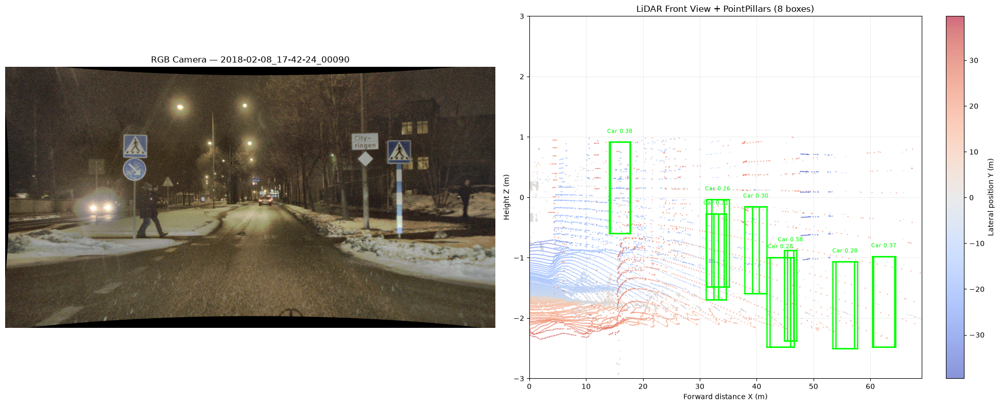

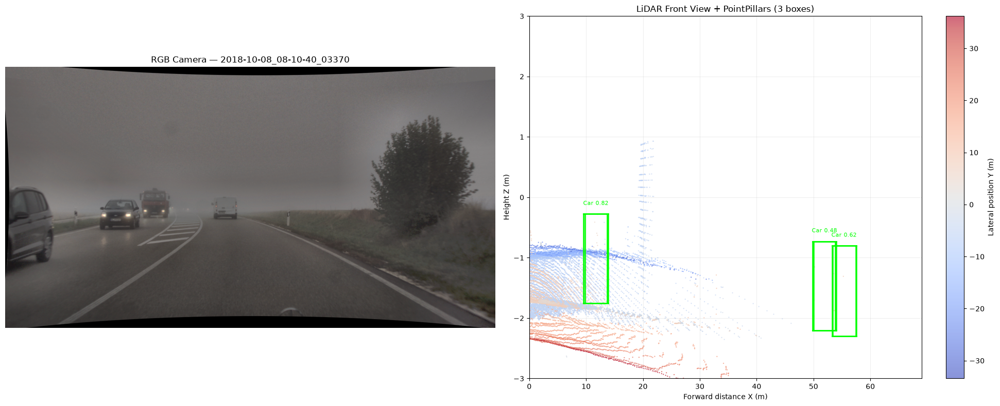

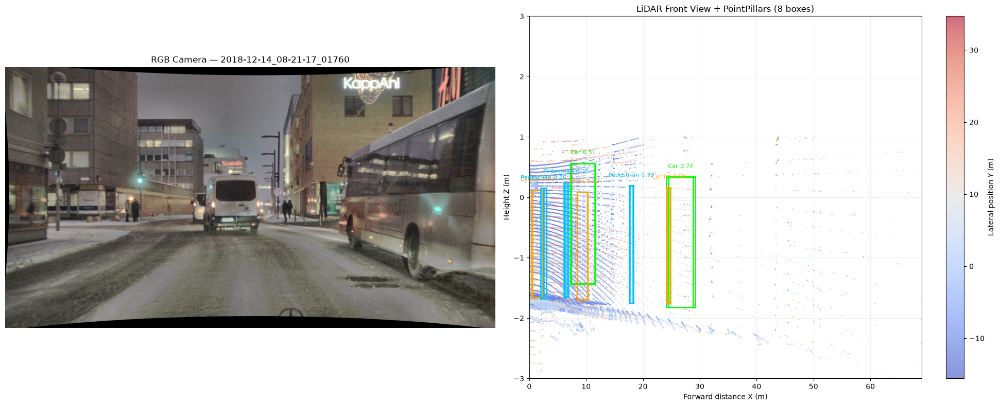

In [71]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Box corners in LiDAR coordinates
def get_box_corners(box):
    cx, cy, cz, dx, dy, dz, yaw = box

    # 8 corners around the box center
    corners = np.array([
        [-dx/2, -dy/2, -dz/2],
        [-dx/2, -dy/2,  dz/2],
        [-dx/2,  dy/2, -dz/2],
        [-dx/2,  dy/2,  dz/2],
        [ dx/2, -dy/2, -dz/2],
        [ dx/2, -dy/2,  dz/2],
        [ dx/2,  dy/2, -dz/2],
        [ dx/2,  dy/2,  dz/2],
    ])

    # Rotate around vertical Z axis
    c, s = np.cos(yaw), np.sin(yaw)
    rotation = np.array([
        [c, -s, 0],
        [s,  c, 0],
        [0,  0, 1]
    ])

    return corners @ rotation.T + np.array([cx, cy, cz])


# Edges connecting the 8 corners
BOX_EDGES = [
    (0, 1), (0, 2), (0, 4),
    (1, 3), (1, 5),
    (2, 3), (2, 6),
    (3, 7),
    (4, 5), (4, 6),
    (5, 7), (6, 7)
]

class_colors = {
    0: "lime",
    1: "deepskyblue",
    2: "orange"
}

class_names = {
    0: "Car",
    1: "Pedestrian",
    2: "Cyclist"
}

for frame_name, result in nms_results.items():

    # Find corresponding LiDAR and RGB files
    lidar_file = next(
        f for f in selected_files if f.stem == frame_name
    )
    rgb_file = RGB_DIR / f"{frame_name}.png"

    # Load original RGB
    rgb = plt.imread(rgb_file)

    # Load and filter LiDAR points
    raw = np.fromfile(
        lidar_file, dtype=np.float32
    ).reshape(-1, 5)

    xyz = raw[:, :3]
    pc_range = model.point_cloud_range

    mask = (
        (xyz[:, 0] >= pc_range[0]) &
        (xyz[:, 1] >= pc_range[1]) &
        (xyz[:, 2] >= pc_range[2]) &
        (xyz[:, 0] < pc_range[3]) &
        (xyz[:, 1] < pc_range[4]) &
        (xyz[:, 2] < pc_range[5])
    )

    points = xyz[mask]

    # Create side-by-side visualization
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    axes[0].imshow(rgb)
    axes[0].set_title(f"RGB Camera — {frame_name}")
    axes[0].axis("off")

    # LiDAR frontal view: X vs Z, colored by Y
    scatter = axes[1].scatter(
        points[:, 0],
        points[:, 2],
        c=points[:, 1],
        cmap="coolwarm",
        s=0.5,
        alpha=0.6
    )

    # Draw predicted 3D boxes
    for box, score, label in zip(
        result["boxes"],
        result["scores"],
        result["labels"]
    ):
        corners = get_box_corners(box)
        color = class_colors[int(label)]

        for start, end in BOX_EDGES:
            axes[1].plot(
                [corners[start, 0], corners[end, 0]],
                [corners[start, 2], corners[end, 2]],
                color=color,
                linewidth=1.8
            )

        axes[1].text(
            box[0],
            box[2] + box[5] / 2 + 0.15,
            f"{class_names[int(label)]} {score:.2f}",
            color=color,
            fontsize=8,
            ha="center"
        )

    axes[1].set_title(
        f"LiDAR Front View + PointPillars ({len(result['scores'])} boxes)"
    )
    axes[1].set_xlabel("Forward distance X (m)")
    axes[1].set_ylabel("Height Z (m)")
    axes[1].set_xlim(0, 69)
    axes[1].set_ylim(-3, 3)
    axes[1].grid(alpha=0.2)

    fig.colorbar(
        scatter,
        ax=axes[1],
        label="Lateral position Y (m)"
    )

    plt.tight_layout()
    plt.show()